# DÉCLIC · Axe 7 (O08) : résultats des réseaux entraînés

Ce notebook montre **les résultats réels** des entraînements PyTorch faits sur Google Colab (GPU)
avec les notebooks `DECLIC_singpad.ipynb`, `DECLIC_yousician.ipynb` et `DECLIC_all.ipynb`.

- Ces notebooks d’entraînement sont gardés vides dans le dépôt : ils s’exécutent sur Colab et
  leurs sorties brutes restent privées sur Drive (chemins, données sources sous licence).
- Chaque entraînement exporte `model.pt`, `metrics.json`, `history.json` et `analysis.json`.
  Ces exports sont versionnés dans `artifacts/models/`. **Ce notebook ne fait que les lire.**
- Rien n’est réentraîné ici, aucun chiffre n’est recalculé à la main, aucune donnée privée
  n’est nécessaire. Il tourne en quelques secondes sur CPU.

Plan : 1) les modèles servis · 2) le checkpoint vérifié et l’architecture · 3) les courbes
d’apprentissage · 4) le test contre des contrôles simples · 5) l’incertitude (bootstrap) ·
6) la calibration · 7) la comparaison d’architectures · 8) les résultats par sous-groupe · 9) les limites.

In [1]:
import json, sys
from pathlib import Path

ROOT = Path.cwd()
while not (ROOT / 'axis7').is_dir():
    if ROOT.parent == ROOT:
        raise SystemExit('Lancer ce notebook depuis le dépôt DÉCLIC.')
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import torch
from axis7 import musical_registry

plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.alpha': .3, 'font.size': 10})
NEURAL, CONTROL, OTHER = '#1F4A72', '#A27C12', '#9AA5B4'

REGISTRY = ROOT / 'artifacts/models/musical-cloud'
ACTIVE = json.loads((REGISTRY / 'active.json').read_text())
load = lambda folder, name: json.loads((folder / name).read_text(encoding='utf-8'))
runs = {}
for source, identifier in ACTIVE.items():
    folder = REGISTRY / identifier
    runs[source] = {'id': identifier, 'folder': folder, 'metrics': load(folder, 'metrics.json'),
                    'history': load(folder, 'history.json'), 'analysis': load(folder, 'analysis.json')}
print('Modèles actifs :', ACTIVE)

Modèles actifs : {'yousician': 'yousician-enhanced_gru-s42-77455ae03f05', 'singpad': 'singpad-enhanced_gru-s42-8576d5ba1d6a'}


## 1. Les modèles servis

Un modèle par base de données. SingPAD : du chant, la cible est la réussite note par note de
l’enregistrement suivant (probabilité). Yousician : de l’ukulélé, la cible est la fraction de
réussite du jour actif suivant (un score entre 0 et 1, **pas** une probabilité).
Les apprenants sont répartis en trois groupes disjoints : un apprenant du test n’a jamais été vu
pendant l’entraînement.

In [2]:
rows = []
for source, run in runs.items():
    m = run['metrics']; s = m['splits']; ex = m.get('execution') or {}
    rows.append([source, m['instrument'], m['target'], m['model'], m['hidden'], m['context'], m['K'],
                 f"{s['train']['count']} / {s['validation']['count']} / {s['test']['count']}",
                 m['epochs_completed'], m['device'], ex.get('torch', 'non noté dans l’export'), ex.get('code_revision', 'non notée dans l’export')[:10]])
head = ['base', 'instrument', 'cible', 'modèle', 'mémoire GRU', 'contexte', 'K concepts',
        'apprenants train / val / test', 'époques', 'matériel', 'torch', 'révision du code']
for r in rows:
    print('\n'.join(f'{h:>30} : {v}' for h, v in zip(head, r)), end='\n\n')

                          base : yousician
                    instrument : ukulele
                         cible : next_active_day_success_fraction
                        modèle : enhanced_gru
                   mémoire GRU : 48
                      contexte : 64
                    K concepts : 1
 apprenants train / val / test : 699 / 150 / 150
                       époques : 12
                      matériel : cuda
                         torch : non noté dans l’export
              révision du code : non notée 

                          base : singpad
                    instrument : voice
                         cible : next_recording_note_success_by_source_concept
                        modèle : enhanced_gru
                   mémoire GRU : 48
                      contexte : 64
                    K concepts : 270
 apprenants train / val / test : 729 / 156 / 157
                       époques : 12
                      matériel : cuda
                         torch : 2.1

## 2. Le checkpoint vérifié et l’architecture

Le modèle n’est pas chargé directement : il passe par `musical_registry.validate`, le même contrôle
que le serveur. Il vérifie l’empreinte SHA-256 du fichier, la provenance des trois partitions
(empreintes distinctes), l’audit chronologique de SingPAD, que les poids sont finis, et que le
réseau fait mieux que la moyenne d’entraînement sur la **validation**. Pour SingPAD, il doit en plus
battre le contrôle le plus fort, choisi sur la validation.
Si un seul contrôle échoue, la cellule s’arrête.

In [3]:
models = {}
for source, run in runs.items():
    meta, model = musical_registry.validate(run['folder'])
    models[source] = model
    print(f"{source} : checkpoint accepté, sha256 {meta['model_sha256'][:16]}…")

if 'audit' in runs['singpad']['metrics']:
    chrono = runs['singpad']['metrics']['audit']['chronology']
    print('\nAudit chronologique SingPAD :', chrono)

model = models['singpad']
print('\n', model)
total = sum(p.numel() for p in model.parameters())
print(f'\nParamètres entraînables : {total:,}'.replace(',', ' '))
for name, module in [('embedding des exercices', model.item), ('GRU (mémoire)', model.encoder),
                     ('tête de sortie', model.output)]:
    print(f"  {name:<26}{sum(p.numel() for p in module.parameters()):>9,}".replace(',', ' '))

yousician : checkpoint accepté, sha256 77455ae03f05c2a2…
singpad : checkpoint accepté, sha256 8576d5ba1d6a2bb2…

Audit chronologique SingPAD : {'learners': 1042, 'time_groups': 18328, 'chronological_inversions': 0, 'duplicate_time_groups': 0}

 EnhancedGRU(
  (item): Embedding(89, 12, padding_idx=0)
  (encoder): GRU(1093, 48, batch_first=True)
  (output): Sequential(
    (0): Linear(in_features=601, out_features=48, bias=True)
    (1): ReLU()
    (2): Linear(in_features=48, out_features=270, bias=True)
  )
)

Paramètres entraînables : 207 786
  embedding des exercices       1 068
  GRU (mémoire)               164 592
  tête de sortie               42 126


Lecture : à chaque pas, le GRU reçoit `4K + 13` nombres (pour SingPAD, K = 270 concepts) :
échecs et réussites du pas précédent, cumuls passés (`log1p`), exercice précédent (embedding de 12)
et une difficulté. Sa mémoire de 48 nombres, l’exercice demandé et les cumuls passent dans une
petite tête (Linéaire → ReLU → Linéaire) qui sort une valeur par concept, puis une sigmoïde.
Le résultat de l’essai à prévoir n’est jamais en entrée.

## 3. Les courbes d’apprentissage

Mesure sur la **validation** après chaque époque. Le checkpoint conservé est celui de la meilleure
log-loss (SingPAD) ou MAE (Yousician) de validation, pas le dernier (`cloud_training.train`). Les exports ne contiennent que la validation par époque, pas la perte
d’entraînement.

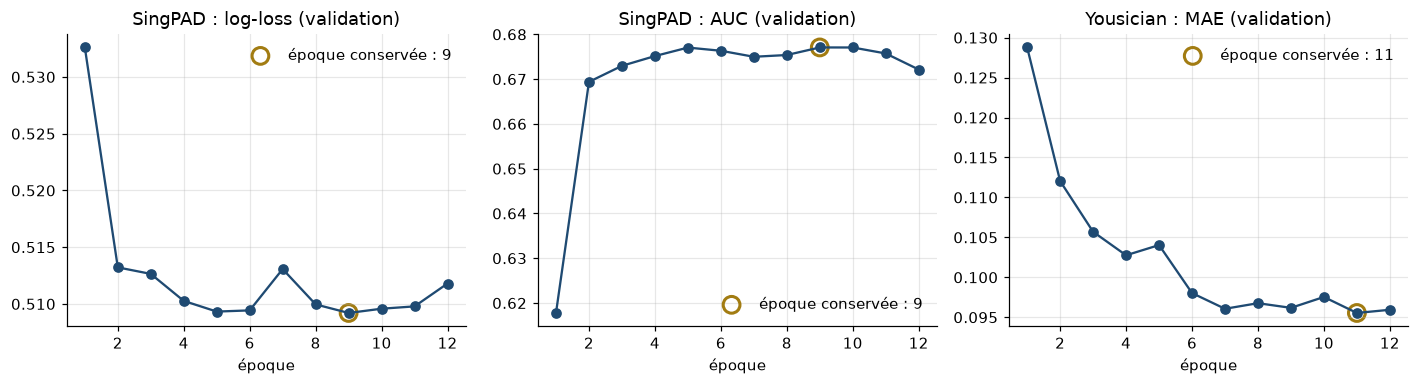

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
SELECT = {'singpad': 'log_loss', 'yousician': 'mae'}  # critère de sélection du checkpoint (le plus bas gagne)
specs = [('singpad', 'log_loss', 'SingPAD : log-loss (validation)'),
         ('singpad', 'roc_auc', 'SingPAD : AUC (validation)'),
         ('yousician', 'mae', 'Yousician : MAE (validation)')]
for ax, (source, key, title) in zip(axes, specs):
    history = runs[source]['history']
    epochs = [h['epoch'] for h in history]; values = [h['validation'][key] for h in history]
    chosen = min(range(len(history)), key=lambda i: history[i]['validation'][SELECT[source]])
    ax.plot(epochs, values, marker='o', color=NEURAL)
    ax.scatter([epochs[chosen]], [values[chosen]], s=120, facecolor='none', edgecolor=CONTROL, linewidth=2,
               label=f'époque conservée : {epochs[chosen]}')
    ax.set_title(title); ax.set_xlabel('époque'); ax.legend(frameon=False)
plt.tight_layout(); plt.show()

## 4. Le test : le réseau contre des contrôles simples

Un réseau ne vaut quelque chose que s’il bat des méthodes simples. Les contrôles :
moyenne d’entraînement, dernier résultat, moyenne des 3 derniers, moyenne exponentielle (EWMA)
et fréquence historique par concept. Le contrôle de référence est **choisi sur la validation**,
avant de regarder le test (`validation_selected_control`). Plus bas = meilleur.

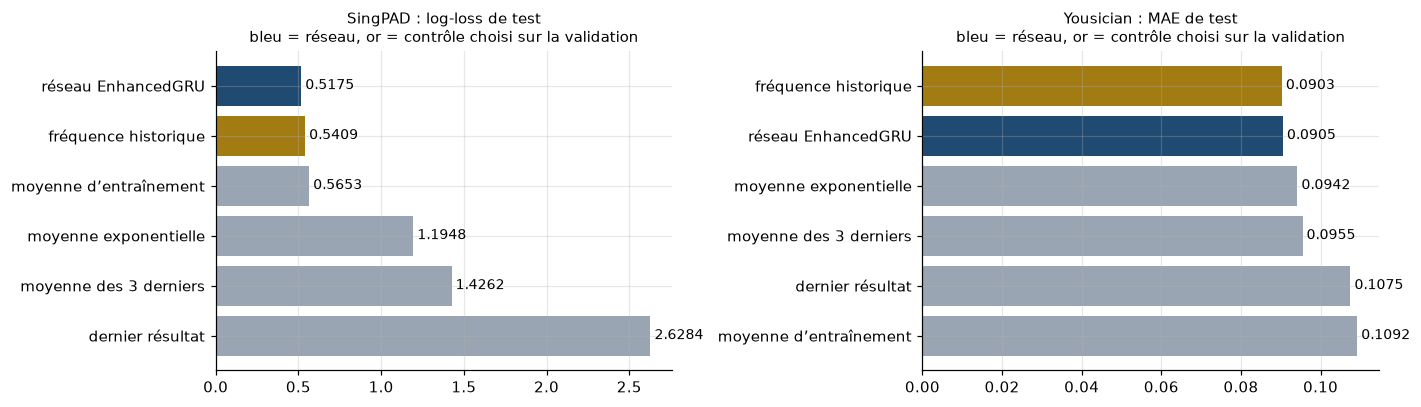

  singpad : réseau 0.5175 contre fréquence historique 0.5409  →  écart -0.0234
yousician : réseau 0.0905 contre fréquence historique 0.0903  →  écart +0.0003


In [5]:
NAMES = {'neural': 'réseau EnhancedGRU', 'train_mean': 'moyenne d’entraînement', 'previous': 'dernier résultat',
         'rolling3': 'moyenne des 3 derniers', 'ewma': 'moyenne exponentielle', 'frequency': 'fréquence historique'}
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
for ax, (source, key, label) in zip(axes, [('singpad', 'log_loss', 'log-loss de test'), ('yousician', 'mae', 'MAE de test')]):
    an = runs[source]['analysis']; chosen = an['validation_selected_control']
    items = sorted(an['metrics'].items(), key=lambda kv: kv[1][key])
    names = [NAMES.get(k, k) for k, _ in items]; values = [v[key] for _, v in items]
    colors = [NEURAL if k == 'neural' else CONTROL if k == chosen else OTHER for k, _ in items]
    ax.barh(names, values, color=colors); ax.invert_yaxis()
    for y, v in enumerate(values): ax.text(v, y, f' {v:.4f}', va='center', fontsize=9)
    ax.set_title(f"{'SingPAD' if source == 'singpad' else 'Yousician'} : {label}\nbleu = réseau, or = contrôle choisi sur la validation", fontsize=9.5)
plt.tight_layout(); plt.show()

for source, key in [('singpad', 'log_loss'), ('yousician', 'mae')]:
    an = runs[source]['analysis']; c = an['validation_selected_control']
    n, k = an['metrics']['neural'][key], an['metrics'][c][key]
    print(f"{source:>9} : réseau {n:.4f} contre {NAMES[c]} {k:.4f}  →  écart {n - k:+.4f}")

## 5. L’incertitude : bootstrap par apprenant

Les apprenants du test sont rééchantillonnés 1 000 fois (un apprenant entier à la fois).
On regarde l’intervalle à 95 % de la **différence appariée** réseau − contrôle :
s’il est entièrement sous zéro, le gain du réseau ne vient pas du hasard du découpage.

In [6]:
for source in runs:
    b = runs[source]['analysis']['bootstrap']; c = runs[source]['analysis']['validation_selected_control']
    low, high = b['paired_neural_minus_control'][c]
    verdict = ('le réseau est meilleur' if high < 0 else
               'le contrôle est meilleur' if low > 0 else 'pas de différence démontrée')
    print(f"{source:>9} ({b['metric']}, {b['learners']} apprenants, {b['repeats']} tirages) : "
          f"réseau − {NAMES[c]} ∈ [{low:+.4f} ; {high:+.4f}]  →  {verdict}")

yousician (mae, 150 apprenants, 1000 tirages) : réseau − fréquence historique ∈ [-0.0011 ; +0.0017]  →  pas de différence démontrée
  singpad (log_loss, 157 apprenants, 1000 tirages) : réseau − fréquence historique ∈ [-0.0286 ; -0.0179]  →  le réseau est meilleur


## 6. La calibration (SingPAD, test)

Quand le réseau annonce 70 %, l’apprenant réussit-il vraiment environ 70 % du temps ?
Chaque point regroupe les prévisions d’une tranche ; la taille du point est le nombre de notes.
Sur la diagonale = bien calibré.

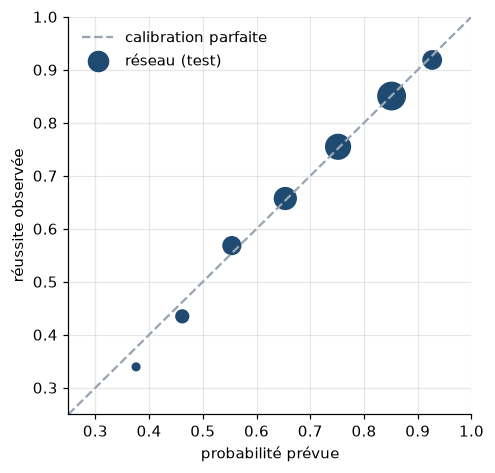

Écart moyen pondéré entre prévu et observé : 0.006


In [7]:
cal = runs['singpad']['analysis']['metrics']['neural']['calibration']
pred = [c['prediction'] for c in cal]; obs = [c['observed'] for c in cal]; weight = [c['label_weight'] for c in cal]
fig, ax = plt.subplots(figsize=(4.6, 4.4))
ax.plot([0, 1], [0, 1], ls='--', color=OTHER, label='calibration parfaite')
ax.scatter(pred, obs, s=[20 + 300 * w / max(weight) for w in weight], color=NEURAL, label='réseau (test)')
ax.set_xlim(.25, 1); ax.set_ylim(.25, 1); ax.set_xlabel('probabilité prévue'); ax.set_ylabel('réussite observée')
ax.legend(frameon=False, loc='upper left'); plt.tight_layout(); plt.show()
gap = sum(abs(p - o) * w for p, o, w in zip(pred, obs, weight)) / sum(weight)
print(f'Écart moyen pondéré entre prévu et observé : {gap:.3f}')

## 7. La comparaison d’architectures (SingPAD, graine 42)

Même données, même partition, même protocole : DKT (Piech et al., 2015), EnhancedGRU et un modèle
à attention inspiré de SAKT. Le modèle servi est l’EnhancedGRU.

In [8]:
phase6 = ROOT / 'artifacts/models/phase6-cloud/singpad'
print(f"{'architecture':<16}{'val log-loss':>14}{'test log-loss':>15}{'test Brier':>12}{'test AUC':>10}")
for name in ['dkt', 'enhanced_gru', 'item_attention']:
    m = load(phase6 / name, 'metrics.json')
    print(f"{name:<16}{m['validation']['log_loss']:>14.4f}{m['test']['log_loss']:>15.4f}"
          f"{m['test']['brier']:>12.4f}{m['test']['roc_auc']:>10.4f}")

architecture      val log-loss  test log-loss  test Brier  test AUC
dkt                     0.5095         0.5185      0.1711    0.6990
enhanced_gru            0.5092         0.5175      0.1709    0.6991
item_attention          0.5098         0.5179      0.1709    0.6976


Lecture honnête : les trois architectures sont **à égalité pratique** (écarts de l’ordre de 0,001).
Le gain vient surtout de la séquence de l’apprenant et des cumuls, pas d’une architecture plus
complexe. L’EnhancedGRU est retenu car il est le meilleur sur la validation et reste simple.

## 8. Résultats par sous-groupe (SingPAD, test)

Descriptif, pas causal. « Historique » = nombre de séances déjà observées pour l’apprenant.
Un écart négatif = le réseau fait mieux. Les petits effectifs ne permettent aucune conclusion :
« exercice jamais vu » ne concerne que 4 apprenants, et en service le modèle s’abstient sur un exercice inconnu.

In [9]:
LABELS = {'history_1_2_groups': 'historique de 1 à 2 séances', 'history_3_9_groups': 'historique de 3 à 9 séances',
          'history_10_plus_groups': 'historique de 10 séances et plus', 'unseen_exercise': 'exercice jamais vu',
          'low_observed_score_under_0_5': 'résultat observé < 0,5', 'high_observed_score_at_least_0_8': 'résultat observé ≥ 0,8',
          'rare_train_concepts': 'concepts rares', 'frequent_train_concepts': 'concepts fréquents'}
print(f"{'sous-groupe':<34}{'apprenants':>11}{'réseau':>9}{'contrôle':>10}{'écart':>9}")
for key, s in runs['singpad']['analysis']['slices'].items():
    n, c = s['neural']['log_loss'], s['control']['log_loss']
    print(f"{LABELS.get(key, key):<34}{s['learners']:>11}{n:>9.4f}{c:>10.4f}{n - c:>+9.4f}")

sous-groupe                        apprenants   réseau  contrôle    écart
historique de 1 à 2 séances               157   0.5049    0.5323  -0.0274
historique de 3 à 9 séances               157   0.5126    0.5369  -0.0243
historique de 10 séances et plus          104   0.5238    0.5456  -0.0218
exercice jamais vu                          4   0.5015    0.4935  +0.0080
résultat observé < 0,5                    156   1.0661    1.0899  -0.0237
résultat observé ≥ 0,8                    157   0.2787    0.2916  -0.0129
concepts rares                            122   0.6053    0.6349  -0.0296
concepts fréquents                        157   0.5145    0.5376  -0.0231


## 9. Conclusion et limites

- **SingPAD (chant)** : le réseau bat tous les contrôles simples sur le test, et l’intervalle
  bootstrap apparié contre le meilleur contrôle est entièrement sous zéro.
- **Yousician (ukulélé)** : le réseau fait jeu égal avec la fréquence historique ; aucun gain
  démontré. On le dit tel quel.
- Les limites déclarées par chaque export sont affichées ci-dessous, sans retouche. La mention
  « no confidence interval » date de l’export d’entraînement : l’analyse a ensuite ajouté le
  bootstrap par apprenant (section 5), mais toujours sur une seule partition et une seule graine.
- Ces réseaux prévoient la suite sur **leur** base (chant, ukulélé). Ils ne valident pas une
  prévision pour le piano ni pour les exercices d’écoute de l’application DÉCLIC.

In [10]:
for source, run in runs.items():
    print(source)
    for limit in run['metrics']['limitations'] + run['analysis']['limitations']:
        print('  -', limit)
    print('  périmètre :', run['metrics']['validation_gate']['scope'])

yousician
  - Learner-disjoint benchmark, not a randomized educational experiment.
  - No generic mastery interpretation or cross-instrument validation.
  - Windowed recurrent memory; counts retain the strictly earlier full prefix.
  - Single fixed split/seed; estimates have no confidence interval.
  - history length is not a validated expertise measure
  - subgroup comparisons are descriptive, not causal
  - unseen exercise slice uses UNK in offline evaluation; serving abstains
  périmètre : source benchmark only; not validation for DEClic piano practice
singpad
  - Learner-disjoint benchmark, not a randomized educational experiment.
  - No generic mastery interpretation or cross-instrument validation.
  - Windowed recurrent memory; counts retain the strictly earlier full prefix.
  - Single fixed split/seed; estimates have no confidence interval.
  - history length is not a validated expertise measure
  - subgroup comparisons are descriptive, not causal
  - unseen exercise slice uses 